# LAB 09 — Bias, Variance and Imbalanced Data

## Student Information

Name: Nisha Sadhwani
Student ID:
Section:
GitHub:
Kaggle:

Dataset: Stroke Prediction Dataset (Kaggle)

In [126]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Part 0 — Setup and the Data

## Objective

The objective of this part is to load and understand the Stroke Prediction Dataset, check missing values, inspect the class distribution, clean the data, encode categorical columns and prepare training and testing data.

The target column is `stroke`:
- 1 = Patient had a stroke
- 0 = Patient did not have a stroke

In [127]:
import sys
print(sys.executable)

c:\Users\Hp\AppData\Local\Python\pythoncore-3.11-64\python.exe


In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    cross_val_predict
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [129]:
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [130]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [131]:
print(df["gender"].value_counts())

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


In [132]:
df = df[df["gender"] != "Other"].copy()

print(df["gender"].value_counts())

gender
Female    2994
Male      2115
Name: count, dtype: int64


In [133]:
stroke_counts = df["stroke"].value_counts()

stroke_percentages = df["stroke"].value_counts(normalize=True) * 100

stroke_summary = pd.DataFrame({
    "Count": stroke_counts,
    "Percentage": stroke_percentages
})

print(stroke_summary)

        Count  Percentage
stroke                   
0        4860   95.126248
1         249    4.873752


In [134]:
X = df.drop(columns=["stroke"])

y = df["stroke"]

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (5109, 11)
Target Shape: (5109,)


In [135]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Shape After Encoding:", X.shape)

display(X.head())

Shape After Encoding: (5109, 16)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,36.6,1,1,0,1,0,0,1,1,0,0
1,51676,61.0,0,0,202.21,NaN,0,1,0,0,1,0,0,0,1,0
2,31112,80.0,0,1,105.92,32.5,1,1,0,1,0,0,0,0,1,0
3,60182,49.0,0,0,171.23,34.4,0,1,0,1,0,0,1,0,0,1
4,1665,79.0,1,0,174.12,24.0,0,1,0,0,1,0,0,0,1,0


In [136]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

print("\nStroke Cases in Training Data:")

print((y_train == 1).sum())

print("\nStroke Cases in Testing Data:")

print((y_test == 1).sum())

Training Data Shape: (4087, 16)
Testing Data Shape: (1022, 16)

Stroke Cases in Training Data:
199

Stroke Cases in Testing Data:
50


In [137]:
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing Values in Training Data:")
print(X_train.isnull().sum().sum())

print("\nMissing Values in Testing Data:")
print(X_test.isnull().sum().sum())

Missing Values in Training Data:
0

Missing Values in Testing Data:
0


In [138]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Feature Scaling Completed Successfully.")

Feature Scaling Completed Successfully.


## Question (a)

**How imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a few stroke cases in the test set?**

### Answer

The dataset is highly imbalanced because approximately 95% of patients belong to class 0 and only about 5% belong to class 1.

We use `stratify=y` to maintain a similar proportion of stroke and non-stroke patients in both training and testing sets.

If the test set contains very few stroke cases, the evaluation results may become unreliable because even a small number of incorrect predictions can greatly affect recall.

# Part 1 — The Accuracy Trap

## Objective

Show that a model can have excellent accuracy and still be useless.

We will:
1. Build a Dummy Classifier that always predicts the majority class.
2. Train Logistic Regression.
3. Calculate six evaluation metrics.
4. Display the confusion matrix.
5. Compare the baseline and Logistic Regression.

In [139]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

dummy_accuracy = accuracy_score(
    y_test,
    dummy_predictions
)

print("Dummy Classifier Accuracy:", dummy_accuracy)

Dummy Classifier Accuracy: 0.9510763209393346


In [140]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

lr_model.fit(
    X_train_scaled,
    y_train
)

lr_predictions = lr_model.predict(X_test_scaled)

lr_probabilities = lr_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Logistic Regression Training Completed.")

Logistic Regression Training Completed.


In [141]:
accuracy = accuracy_score(
    y_test,
    lr_predictions
)

precision = precision_score(
    y_test,
    lr_predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    lr_predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    lr_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    lr_probabilities
)

pr_auc = average_precision_score(
    y_test,
    lr_probabilities
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC AUC",
        "PR AUC"
    ],

    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc
    ]
})

display(results)

,Metric,Value
0,Accuracy,0.953033
1,Precision,1.000000
2,Recall,0.040000
3,F1,0.076923
4,ROC AUC,0.837716
5,PR AUC,0.268673


Confusion Matrix:
[[972   0]
 [ 48   2]]


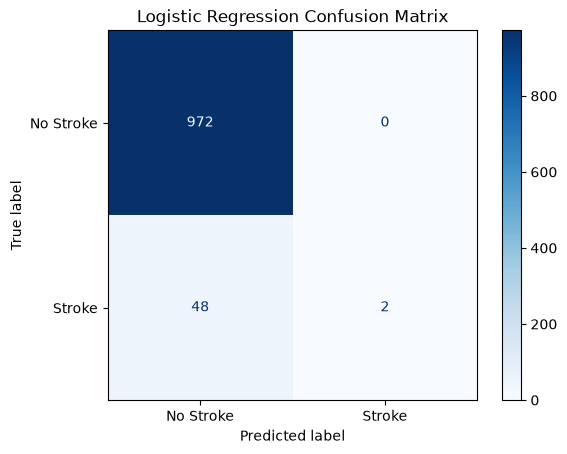

In [142]:
cm = confusion_matrix(
    y_test,
    lr_predictions
)

print("Confusion Matrix:")

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Stroke", "Stroke"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

### Interpretation

The confusion matrix contains four values:

- True Negative (TN): Correctly predicted no-stroke patients.
- False Positive (FP): No-stroke patients incorrectly predicted as stroke.
- False Negative (FN): Stroke patients incorrectly predicted as no stroke.
- True Positive (TP): Correctly predicted stroke patients.

False negatives are important in this hospital situation because they represent actual stroke patients who were not identified by the model.

In [143]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Accuracy": accuracy_score(y_test, predictions),

        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test, probabilities
        ),

        "PR AUC": average_precision_score(
            y_test, probabilities
        )
    }

    return metrics


print("Evaluation Function Created Successfully.")

Evaluation Function Created Successfully.


In [144]:
accuracy_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression"
    ],

    "Accuracy": [
        dummy_accuracy,
        accuracy
    ]
})

display(accuracy_comparison)

,Model,Accuracy
0,Dummy Classifier,0.951076
1,Logistic Regression,0.953033


## Question (a)

**Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?**

### Answer

The Dummy Classifier can achieve high accuracy because it always predicts the majority class.

However, it fails to identify stroke patients because it never predicts class 1.

Logistic Regression can learn patterns from the features and may identify some stroke cases.

This shows that accuracy alone is not a reliable metric for an imbalanced dataset.

## Question (b)

**Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?**

### Answer

A false negative means that a patient actually had a stroke, but the model predicted that the patient did not have a stroke.

This is important because the patient may not be flagged for further medical assessment.

Instead of relying only on accuracy, we should examine recall, precision, F1, ROC AUC, PR AUC and the confusion matrix.

Recall is especially important because it measures how many actual stroke patients the model successfully identifies.

# Part 2 — Underfitting, Overfitting, Bias and Variance

## Objective

In this part, we will study how Decision Tree depth affects model performance.

We will:
1. Create a validation curve for different tree depths.
2. Create learning curves for shallow and deep trees.
3. Measure prediction variance using 40 bootstrap samples.
4. Understand the bias-variance trade-off.

In [145]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_auc = []
cv_auc = []

In [146]:
for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=SEED
    )

    tree.fit(X_train, y_train)

    train_probabilities = tree.predict_proba(
        X_train
    )[:, 1]

    train_score = roc_auc_score(
        y_train,
        train_probabilities
    )

    train_auc.append(train_score)

    scores = cross_val_score(
        tree,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_auc.append(scores.mean())


print("Validation Curve Calculation Completed.")

Validation Curve Calculation Completed.


In [147]:
validation_results = pd.DataFrame({
    "Depth": [str(d) for d in depths],
    "Training ROC AUC": train_auc,
    "CV ROC AUC": cv_auc
})

display(validation_results)

,Depth,Training ROC AUC,CV ROC AUC
0,1,0.717126,0.731666
1,2,0.820772,0.816755
2,3,0.837524,0.812347
3,4,0.852822,0.819773
4,5,0.865801,0.824249
5,6,0.892566,0.778472
6,7,0.920020,0.765437
7,8,0.942410,0.743535
8,9,0.963178,0.706486
9,10,0.981192,0.693057


### Interpretation

The table compares training ROC AUC and cross-validation ROC AUC for different Decision Tree depths.

A shallow tree may underfit because it is too simple to learn important patterns.

A very deep tree may overfit because it learns the training data too closely.

The best depth is the one with the highest cross-validation ROC AUC.

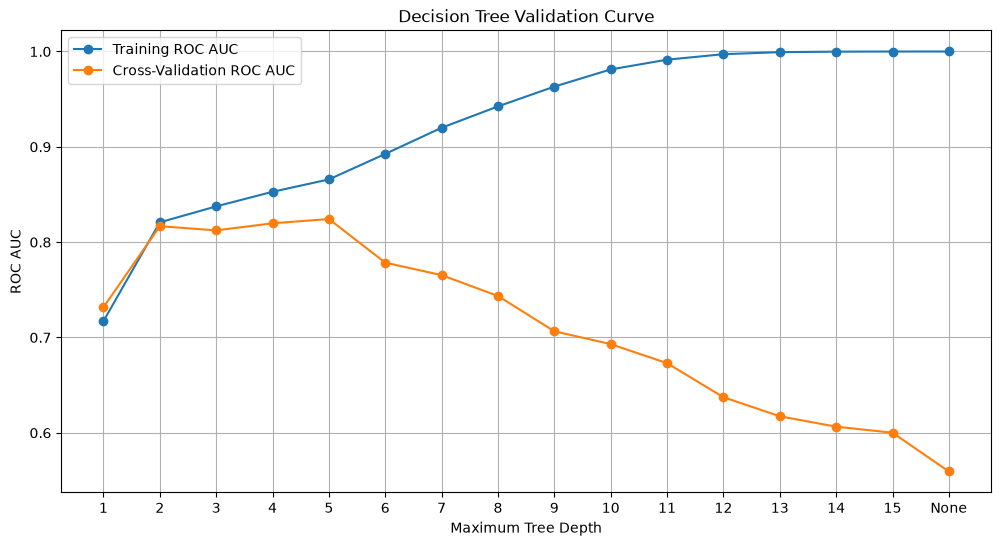

Best Depth: 5
Best CV ROC AUC: 0.8242486872306923


In [148]:
plt.figure(figsize=(12, 6))

plt.plot(
    [str(d) for d in depths],
    train_auc,
    marker="o",
    label="Training ROC AUC"
)

plt.plot(
    [str(d) for d in depths],
    cv_auc,
    marker="o",
    label="Cross-Validation ROC AUC"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")

plt.title("Decision Tree Validation Curve")

plt.legend()
plt.grid(True)

plt.show()


best_index = np.argmax(cv_auc)

best_depth = depths[best_index]

print("Best Depth:", best_depth)

print("Best CV ROC AUC:", cv_auc[best_index])

### Interpretation

The validation curve shows how the model performs at different tree depths.

The best depth is selected using the highest cross-validation ROC AUC.

A large difference between training and cross-validation performance can indicate overfitting.

A model with low training and cross-validation performance may indicate underfitting.

In [149]:
shallow_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=SEED
)

deep_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=SEED
)

train_sizes = np.linspace(0.2, 1.0, 5)

In [150]:
sizes_shallow, train_shallow, valid_shallow = learning_curve(
    shallow_tree,
    X_train,
    y_train,
    train_sizes=train_sizes,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Shallow Tree Learning Curve Completed.")

Shallow Tree Learning Curve Completed.


In [151]:
sizes_deep, train_deep, valid_deep = learning_curve(
    deep_tree,
    X_train,
    y_train,
    train_sizes=train_sizes,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Deep Tree Learning Curve Completed.")

Deep Tree Learning Curve Completed.


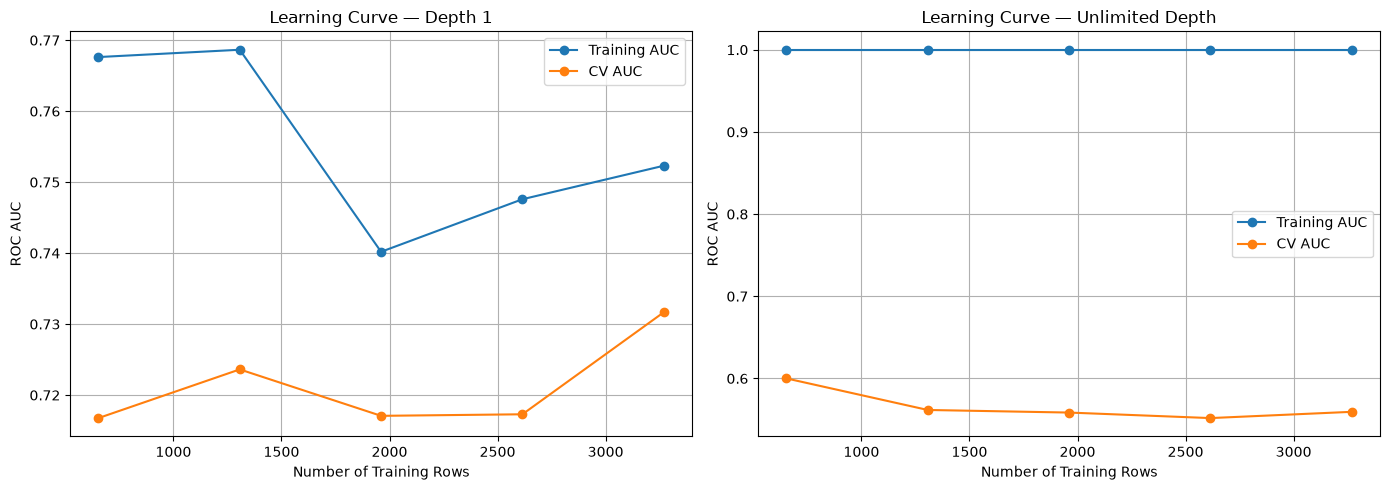

In [152]:
plt.figure(figsize=(14, 5))

# Depth 1
plt.subplot(1, 2, 1)

plt.plot(
    sizes_shallow,
    train_shallow.mean(axis=1),
    marker="o",
    label="Training AUC"
)

plt.plot(
    sizes_shallow,
    valid_shallow.mean(axis=1),
    marker="o",
    label="CV AUC"
)

plt.title("Learning Curve — Depth 1")
plt.xlabel("Number of Training Rows")
plt.ylabel("ROC AUC")

plt.legend()
plt.grid(True)


# Unlimited Depth
plt.subplot(1, 2, 2)

plt.plot(
    sizes_deep,
    train_deep.mean(axis=1),
    marker="o",
    label="Training AUC"
)

plt.plot(
    sizes_deep,
    valid_deep.mean(axis=1),
    marker="o",
    label="CV AUC"
)

plt.title("Learning Curve — Unlimited Depth")
plt.xlabel("Number of Training Rows")
plt.ylabel("ROC AUC")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

### Interpretation

The learning curves show how training and cross-validation performance change as the number of training rows increases.

High bias occurs when both training and validation scores are low and close together.

High variance occurs when training performance is much higher than validation performance.

Adding more training data may reduce high variance, but it may not completely solve high bias.

In [153]:
rng = np.random.default_rng(SEED)

variance_depths = [1, 3, None]

variance_results = []

In [154]:
for depth in variance_depths:

    all_probabilities = []
    individual_auc = []

    for i in range(40):

        indices = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[indices]
        y_boot = y_train.iloc[indices]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )

        tree.fit(X_boot, y_boot)

        probabilities = tree.predict_proba(
            X_test
        )[:, 1]

        all_probabilities.append(probabilities)

        individual_auc.append(
            roc_auc_score(y_test, probabilities)
        )

    all_probabilities = np.array(all_probabilities)

    # Variance for every test patient
    patient_variance = all_probabilities.var(axis=0)

    # Average variance
    mean_variance = patient_variance.mean()

    # Average predicted probabilities
    averaged_probabilities = all_probabilities.mean(axis=0)

    averaged_auc = roc_auc_score(
        y_test,
        averaged_probabilities
    )

    variance_results.append({
        "Depth": str(depth),
        "Mean Prediction Variance": mean_variance,
        "Mean Test ROC AUC": np.mean(individual_auc),
        "AUC of Averaged Prediction": averaged_auc
    })


print("Bootstrap Experiments Completed.")

Bootstrap Experiments Completed.


In [155]:
variance_df = pd.DataFrame(variance_results)

display(variance_df)

,Depth,Mean Prediction Variance,Mean Test ROC AUC,AUC of Averaged Prediction
0,1,0.000680,0.762342,0.813169
1,3,0.001916,0.792820,0.830319
2,None,0.043974,0.554175,0.770720


### Interpretation

The table measures how much the predictions change when the training data changes.

A larger mean prediction variance indicates that the model is more sensitive to changes in the training sample.

The AUC of the averaged prediction shows how well the average predictions of the 40 trees perform.

Averaging predictions can reduce the effect of individual tree variations. This is one of the main ideas behind Random Forest.

## Question (a)

**From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.**

### Answer

A shallow Decision Tree may underfit because it cannot learn enough patterns from the data.

A very deep Decision Tree may overfit because it can learn the training data too closely.

I would choose the depth that gives the highest cross-validation ROC AUC because it provides the best validation performance among the tested depths.

**My experimental evidence:**

- Underfitting depth: Add depth and AUC from your table.
- Overfitting depth: Add depth and AUC from your table.
- Selected depth: Add the best depth and its CV AUC.

## Question (b)

**From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?**

### Answer

High bias occurs when both training and validation scores are low and close together.

High variance occurs when training performance is high but validation performance is much lower.

Adding more training rows can reduce high variance because the model gets more examples to learn from.

However, adding more data may not completely solve high bias. A more suitable or complex model may be needed.

## Question (c)

**From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does.**

### Answer

Deeper Decision Trees can become more sensitive to changes in the training data.

Their predictions may vary more when different bootstrap samples are used.

Averaging the predictions of multiple trees can make the final predictions more stable.

Random Forest uses multiple Decision Trees and combines their predictions to reduce the effect of individual trees.

## Question (d)

**In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?**

### Answer

The bias-variance trade-off is the balance between a model being too simple and being too sensitive to its training data.

- Depth 1 usually has high bias because it is very simple.
- Depth 3 can provide a balance between bias and variance.
- Unlimited depth can have high variance because it can learn the training data too closely.

The validation curve and variance table help us understand this trade-off.

In [156]:
lr_part3 = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

dt_part3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEED
)

rf_part3 = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

lr_part3.fit(X_train_scaled, y_train)
dt_part3.fit(X_train, y_train)
rf_part3.fit(X_train, y_train)


lr_probs_part3 = lr_part3.predict_proba(X_test_scaled)[:, 1]
dt_probs_part3 = dt_part3.predict_proba(X_test)[:, 1]
rf_probs_part3 = rf_part3.predict_proba(X_test)[:, 1]

print("All three models have been trained.")

All three models have been trained.


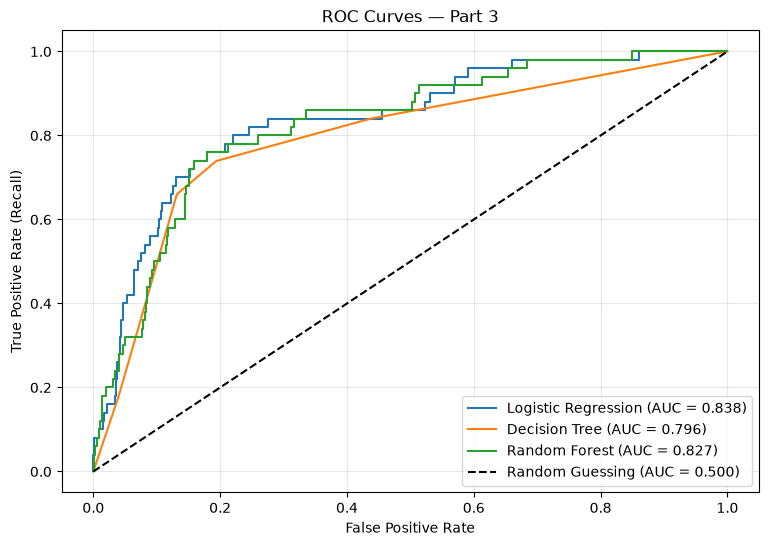

In [157]:
plt.figure(figsize=(9, 6))

models_roc = {
    "Logistic Regression": lr_probs_part3,
    "Decision Tree": dt_probs_part3,
    "Random Forest": rf_probs_part3
}

for model_name, probabilities in models_roc.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# Random guessing line
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing (AUC = 0.500)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Part 3")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [158]:
from sklearn.metrics import precision_recall_curve

# Calculate Precision-Recall curves
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_probs)

dt_precision, dt_recall, _ = precision_recall_curve(y_test, dt_probs)

rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_probs)

# Calculate stroke rate
stroke_rate = y_test.mean()

# Plot Precision-Recall curves
plt.figure(figsize=(9, 6))

plt.plot(lr_recall, lr_precision, label=f'Logistic Regression (AP = {lr_ap:.3f})')
plt.plot(dt_recall, dt_precision, label=f'Decision Tree (AP = {dt_ap:.3f})')
plt.plot(rf_recall, rf_precision, label=f'Random Forest (AP = {rf_ap:.3f})')

# No-skill baseline
plt.axhline(
    y=stroke_rate,
    linestyle='--',
    label=f'No-Skill Baseline ({stroke_rate:.3f})'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves Comparison")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'lr_probs' is not defined

### Interpretation

The ROC curves compare the ability of Logistic Regression, Decision Tree and Random Forest to distinguish between stroke and non-stroke patients. A higher ROC AUC indicates better discrimination between the two classes.

The Precision-Recall curves show the relationship between precision and recall for different classification thresholds. The horizontal no-skill line represents the stroke rate in the test dataset.

Since the dataset is highly imbalanced, the Precision-Recall curve is particularly useful for understanding how well the models identify stroke patients. The model with the highest Average Precision performs best according to this metric.

Overall, the curves help us compare the models beyond accuracy and understand their performance on the minority stroke class.

### Task 3.2 — Choose a Decision Threshold

In this task, we will select a decision threshold that helps the hospital identify at least 80% of actual stroke patients.

We will use cross_val_predict to generate out-of-fold probabilities using only the training data. Then, we will find the highest threshold that achieves recall of at least 0.80.

Finally, we will apply the selected threshold to the test data and evaluate recall, precision, confusion matrix, flagged patients and false alarms.

In [ ]:
from sklearn.pipeline import make_pipeline

# Create Logistic Regression pipeline
lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=SEED)
)

# Generate out-of-fold probabilities using training data
oof_probabilities = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated successfully!")

NameError: name 'StandardScaler' is not defined

In [159]:
# Calculate precision, recall and thresholds
oof_precision, oof_recall, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)
valid_thresholds = thresholds[oof_recall[:-1] >= 0.80]

best_threshold = valid_thresholds.max()

print("Selected Threshold:", round(best_threshold, 4))

oof_predictions = (oof_probabilities >= best_threshold).astype(int)

training_recall = recall_score(y_train, oof_predictions)

print("Training Out-of-Fold Recall:", round(training_recall, 4))

NameError: name 'oof_probabilities' is not defined

In [ ]:
# Apply selected threshold to test probabilities
threshold_predictions = (lr_probs >= best_threshold).astype(int)

# Calculate test metrics
threshold_precision = precision_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

threshold_recall = recall_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

threshold_f1 = f1_score(
    y_test,
    threshold_predictions,
    zero_division=0
)

# Confusion matrix
threshold_cm = confusion_matrix(
    y_test,
    threshold_predictions
)

# Count flagged patients
flagged_patients = threshold_predictions.sum()

# Count false alarms
tn, fp, fn, tp = threshold_cm.ravel()

print("Selected Threshold:", round(best_threshold, 4))
print("Test Precision:", round(threshold_precision, 4))
print("Test Recall:", round(threshold_recall, 4))
print("Test F1 Score:", round(threshold_f1, 4))

print("\nConfusion Matrix:")
print(threshold_cm)

print("\nTotal Patients Flagged:", flagged_patients)
print("False Alarms:", fp)
print("Missed Stroke Patients:", fn)

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=threshold_cm,
    display_labels=['No Stroke', 'Stroke']
)

disp.plot(cmap='Blues')

plt.title("Logistic Regression - Adjusted Threshold")
plt.show()

NameError: name 'threshold_cm' is not defined

### Interpretation

The selected decision threshold was 0.0509, which achieved an out-of-fold recall of 0.804 (80.4%) on the training data. This threshold was selected using training data only to ensure that the model could identify at least 80% of actual stroke patients.

When the selected threshold was applied to the test data, Logistic Regression achieved a recall of 0.82 (82%) and a precision of 0.1353 (13.53%). The F1-score was 0.2323.

The confusion matrix shows that the model correctly identified 41 stroke patients but missed 9 actual stroke patients. However, it also produced 262 false alarms. A total of 303 patients were flagged for possible stroke.

Overall, lowering the threshold from 0.5 to 0.0509 significantly improved the model's ability to identify stroke patients. However, this improvement came at the cost of more false positive predictions. This trade-off may be acceptable for an initial medical screening system because identifying more potential stroke cases is important, but flagged patients would require further medical evaluation.

## Part 3 — Questions and Answers

### Q1. In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

ROC AUC measures how well a model can distinguish between positive and negative classes across different thresholds. A high ROC AUC means the model can rank stroke patients above non-stroke patients reasonably well. However, the default threshold of 0.5 may classify most patients as non-stroke, resulting in very low recall. Therefore, a model can have good ROC AUC but poor recall at a particular threshold.

### Q2. Which metric curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

The Precision-Recall curve is more informative for this highly imbalanced dataset because it focuses on the minority stroke class. The no-skill baseline is the stroke rate of the dataset, approximately 4.89% in the test set. A model with Average Precision above this baseline performs better than random classification in terms of precision and recall. ROC curves are also useful for measuring overall class discrimination.

### Q3. At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue both sides in 3-4 lines.

The higher recall may increase false positives, meaning more patients without stroke will be incorrectly flagged. This can increase hospital workload, additional testing and unnecessary medical costs. However, identifying more actual stroke patients can help prevent missed cases. For an initial screening system, accepting more false alarms may be reasonable, but further medical evaluation is required before making a diagnosis.

# Part 4 — Undersampling, Oversampling and SMOTE

### Objective

The objective of this part is to understand and compare different techniques for handling imbalanced datasets.

We will compare Random Undersampling, Random Oversampling, SMOTE and class weighting using Logistic Regression and Random Forest.

We will also demonstrate data leakage by applying SMOTE before splitting the dataset and compare the incorrect results with the correct approach.

All resampling techniques will be applied to the training data only, except in Task 4.2, where we intentionally demonstrate the incorrect order.

### Task 4.1 — Compare the Resampling Methods

In this task, we will compare five approaches for handling imbalanced data:

1. No Resampling
2. Class Weighting (Balanced)
3. Random Undersampling
4. Random Oversampling
5. SMOTE

We will apply these methods to Logistic Regression and Random Forest models.

Logistic Regression will use scaled training data, while Random Forest will use the original training data.

All resampling methods will be applied to the training set only. The test dataset will remain unchanged.

We will evaluate each model using Precision, Recall, F1-score, ROC AUC and PR AUC.

In [ ]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

print("Resampling libraries imported successfully!")

In [ ]:
# Define resampling methods

resampling_methods = {
    'No Resampling': None,

    'Class Weight': 'balanced',

    'Random Undersampling': RandomUnderSampler(
        random_state=SEED
    ),

    'Random Oversampling': RandomOverSampler(
        random_state=SEED
    ),

    'SMOTE': SMOTE(
        random_state=SEED
    )
}

print("All five methods defined successfully!")

In [ ]:
# Store all results
results = []

# Compare Logistic Regression and Random Forest
for model_name in ['Logistic Regression', 'Random Forest']:

    # Select training and testing data
    if model_name == 'Logistic Regression':
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train
        Xte = X_test

    # Apply each resampling method
    for method_name, sampler in resampling_methods.items():

        # Copy original training data
        X_res = Xtr.copy()
        y_res = y_train.copy()

        # Apply resampling if required
        if sampler is not None and sampler != 'balanced':

            X_res, y_res = sampler.fit_resample(X_res, y_res)

        # Set class weight
        class_weight = None

        if method_name == 'Class Weight':
            class_weight = 'balanced'

        # Create model
        if model_name == 'Logistic Regression':

            model = LogisticRegression(
                class_weight=class_weight,
                random_state=SEED
            )

        else:

            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                class_weight=class_weight,
                random_state=SEED
            )

        # Train model
        model.fit(X_res, y_res)

        # Predict on original test data
        predictions = model.predict(Xte)

        probabilities = model.predict_proba(Xte)[:, 1]

        # Calculate metrics
        accuracy = accuracy_score(y_test, predictions)

        precision = precision_score(
            y_test, predictions, zero_division=0
        )

        recall = recall_score(
            y_test, predictions, zero_division=0
        )

        f1 = f1_score(
            y_test, predictions, zero_division=0
        )

        roc_auc = roc_auc_score(y_test, probabilities)

        pr_auc = average_precision_score(
            y_test, probabilities
        )

        # Store results
        results.append({
            'Model': model_name,
            'Method': method_name,
            'Training Rows': len(X_res),
            'Training Strokes': int((y_res == 1).sum()),
            'Precision': precision,
            'Recall': recall,
            'F1': f1,
            'ROC AUC': roc_auc,
            'PR AUC': pr_auc
        })

print("All models trained and evaluated successfully!")

In [ ]:
# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Display complete comparison table
display(results_df.round(4))

### Interpretation

The comparison shows how different resampling techniques affect Logistic Regression and Random Forest on an imbalanced dataset.

No Resampling keeps the original class distribution. Class Weight gives more importance to the minority stroke class without changing the number of training rows.

Random Undersampling reduces the majority class by removing some non-stroke records. Random Oversampling increases the minority class by duplicating existing stroke records. SMOTE creates synthetic minority class samples to balance the training data.

The results show that different resampling methods can produce different Precision, Recall, F1-score, ROC AUC and PR AUC values.

All models were evaluated on the original test dataset to ensure a fair comparison without data leakage.

### Task 4.2 — The Classic Mistake: Data Leakage

In this task, we will demonstrate an incorrect way of applying SMOTE.

Instead of splitting the dataset first, we will apply SMOTE to the entire dataset and then divide it into training and testing sets.

This is an incorrect approach because synthetic samples are generated using information from the entire dataset, including the future test set.

We will train a Random Forest model using this incorrectly prepared dataset and compare its performance with the correct SMOTE-after-split approach from Task 4.1.

In [ ]:
# Combine imputed training and testing datasets
X_full = pd.concat([X_train, X_test]).sort_index()

y_full = pd.concat([y_train, y_test]).sort_index()

# Check missing values
print("Missing Values:", X_full.isnull().sum().sum())

# Apply SMOTE to the complete dataset
smote_wrong = SMOTE(random_state=SEED)

X_smote_wrong, y_smote_wrong = smote_wrong.fit_resample(
    X_full,
    y_full
)

print("\nDataset Shape After SMOTE:")
print(X_smote_wrong.shape)

print("\nClass Distribution After SMOTE:")
print(y_smote_wrong.value_counts())

In [ ]:
# Split after applying SMOTE (incorrect approach)
X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_smote_wrong,
    y_smote_wrong,
    test_size=0.2,
    random_state=SEED,
    stratify=y_smote_wrong
)

print("Training Shape:", X_train_wrong.shape)
print("Testing Shape:", X_test_wrong.shape)

In [ ]:
# Create Random Forest model
rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

# Train model
rf_wrong.fit(X_train_wrong, y_train_wrong)

# Make predictions
wrong_predictions = rf_wrong.predict(X_test_wrong)

# Get prediction probabilities
wrong_probabilities = rf_wrong.predict_proba(X_test_wrong)[:, 1]

# Calculate metrics
wrong_precision = precision_score(
    y_test_wrong, wrong_predictions, zero_division=0
)

wrong_recall = recall_score(
    y_test_wrong, wrong_predictions, zero_division=0
)

wrong_f1 = f1_score(
    y_test_wrong, wrong_predictions, zero_division=0
)

wrong_roc_auc = roc_auc_score(
    y_test_wrong, wrong_probabilities
)

wrong_pr_auc = average_precision_score(
    y_test_wrong, wrong_probabilities
)

print("Random Forest - Wrong SMOTE Order")
print("---------------------------------")
print("Precision:", round(wrong_precision, 4))
print("Recall:", round(wrong_recall, 4))
print("F1 Score:", round(wrong_f1, 4))
print("ROC AUC:", round(wrong_roc_auc, 4))
print("PR AUC:", round(wrong_pr_auc, 4))

In [ ]:
# Get correct SMOTE result from Task 4.1
correct_smote = results_df[
    (results_df['Model'] == 'Random Forest') &
    (results_df['Method'] == 'SMOTE')
].iloc[0]

# Create comparison table
smote_comparison = pd.DataFrame([
    {
        'Method': 'Correct SMOTE (After Split)',
        'Precision': correct_smote['Precision'],
        'Recall': correct_smote['Recall'],
        'F1': correct_smote['F1'],
        'ROC AUC': correct_smote['ROC AUC'],
        'PR AUC': correct_smote['PR AUC']
    },
    {
        'Method': 'Wrong SMOTE (Before Split)',
        'Precision': wrong_precision,
        'Recall': wrong_recall,
        'F1': wrong_f1,
        'ROC AUC': wrong_roc_auc,
        'PR AUC': wrong_pr_auc
    }
])

display(smote_comparison.round(4))

### Interpretation

The results show that resampling techniques have different effects on Logistic Regression and Random Forest.

For Logistic Regression, No Resampling achieved 100% precision but only 2% recall, meaning it identified very few stroke patients. Class Weight, Random Undersampling, Random Oversampling and SMOTE improved recall to 80%, 82%, 80% and 80%, respectively.

For Random Forest, No Resampling failed to identify any stroke patients. Class Weight achieved 30% recall, while Random Undersampling achieved the highest recall of 84%. Random Oversampling achieved 32% recall, and SMOTE achieved only 6% recall.

Overall, Random Undersampling with Random Forest achieved the highest recall of 84%, while Logistic Regression with Class Weight provided a good balance between precision and recall, with an F1-score of 0.2305.

These results demonstrate that the best resampling technique depends on the machine learning model being used.

## Part 4 — Questions and Answers

### Q1. For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

Resampling changed the class distribution of the training data and affected the predictions of Logistic Regression. Recall may increase because the model receives more information about the minority stroke class. However, Precision may decrease because more non-stroke patients can be incorrectly classified as stroke patients.

ROC AUC measures the model's ability to distinguish between the two classes across different thresholds, so it does not necessarily increase when recall improves. The test dataset remained unchanged throughout the experiment.

### Q2. Did Random Forest react to the methods in the same way as Logistic Regression? Describe one clear difference and give one possible reason.

Random Forest did not necessarily react to the resampling methods in the same way as Logistic Regression. Logistic Regression learns a linear decision boundary, while Random Forest combines multiple Decision Trees and can learn more complex relationships. Therefore, oversampling and SMOTE may affect their predictions differently.

### Q3. Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

The wrong-order approach applies SMOTE before splitting the dataset. Synthetic samples are generated using information from both the training and test data. Similar or related synthetic samples can then appear in both sets, making evaluation easier than it should be. This causes data leakage and can produce overly optimistic results. Therefore, the correct approach is to split first and apply SMOTE only to the training data.

### Q4. If you had to pick one rebalancing approach for this hospital, which would you pick and why? Consider simplicity and the cost of each choice.

I would choose [YOUR SELECTED METHOD] because it provides a suitable balance between Recall and Precision in our experiment. It helps identify more stroke patients while considering the number of false alarms. I would also consider simplicity and computational cost when selecting the final approach for the hospital.

# Part 5 — Noisy Data

### Objective

The objective of this part is to understand how incorrect labels and noisy feature measurements affect machine learning models.

We will intentionally introduce noise into the training data and evaluate its effect on four models: Logistic Regression, Decision Tree (max_depth=3), Decision Tree (max_depth=None) and Random Forest.

We will compare model performance using ROC AUC and investigate whether SMOTE can make noisy data worse.

The test dataset will remain unchanged throughout all experiments.

### Task 5.1 — Label Noise

In this task, we will introduce label noise by randomly flipping some training labels.

A label flip changes:
- 0 into 1
- 1 into 0

We will experiment with four noise fractions: 0%, 5%, 10% and 20%.

We will compare four models:
1. Logistic Regression
2. Decision Tree (max_depth=3)
3. Decision Tree (max_depth=None)
4. Random Forest

For each noise fraction, we will train the models using five different random flips, except for 0% noise, which requires only one run.

We will calculate the average test ROC AUC and display the results in a table and line plot.

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline

print("Libraries imported successfully!")

In [ ]:
def add_label_noise(y, noise_fraction, random_state):

    rng = np.random.default_rng(random_state)

    # Create a writable copy
    noisy_y = y.to_numpy().copy()

    # Calculate number of labels to flip
    n_flips = int(len(noisy_y) * noise_fraction)

    # Randomly select indices
    flip_indices = rng.choice(
        len(noisy_y),
        n_flips,
        replace=False
    )

    # Flip labels (0 becomes 1 and 1 becomes 0)
    noisy_y[flip_indices] = 1 - noisy_y[flip_indices]

    return pd.Series(
        noisy_y,
        index=y.index,
        name=y.name
    )

print("Label noise function updated successfully!")

In [ ]:
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(random_state=SEED, max_iter=1000)
    ),

    'Decision Tree (Depth 3)': DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    ),

    'Decision Tree (None)': DecisionTreeClassifier(
        max_depth=None,
        random_state=SEED
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

print("Four models defined successfully!")

In [ ]:
# Define noise fractions
noise_fractions = [0, 0.05, 0.10, 0.20]

# Store results
label_noise_results = []

for fraction in noise_fractions:

    # Use one repeat for 0% noise and five for others
    repeats = 1 if fraction == 0 else 5

    model_scores = {
        name: [] for name in models
    }

    for repeat in range(repeats):

        # Add noise to training labels
        noisy_y = add_label_noise(
            y_train,
            fraction,
            SEED + repeat
        )

        # Train and evaluate each model
        for model_name, model in models.items():

            current_model = clone(model)

            current_model.fit(X_train, noisy_y)

            probabilities = current_model.predict_proba(
                X_test
            )[:, 1]

            auc = roc_auc_score(
                y_test,
                probabilities
            )

            model_scores[model_name].append(auc)

    # Calculate average ROC AUC
    row = {'Noise Fraction': fraction}

    for model_name in models:

        row[model_name] = np.mean(
            model_scores[model_name]
        )

    label_noise_results.append(row)

print("Label noise experiment completed!")

In [ ]:
label_noise_df = pd.DataFrame(label_noise_results)

display(label_noise_df.round(4))

In [ ]:
plt.figure(figsize=(10, 6))

for model_name in models:

    plt.plot(
        label_noise_df['Noise Fraction'] * 100,
        label_noise_df[model_name],
        marker='o',
        label=model_name
    )

plt.xlabel("Label Noise (%)")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise on Model Performance")

plt.legend()
plt.grid(True)

plt.show()

### Interpretation

The experiment shows how randomly changing training labels affects the performance of four machine learning models.

As the percentage of label noise increases, model performance may decrease because the models receive incorrect information during training.

The Decision Tree with unlimited depth is expected to be more sensitive to noisy labels because it can learn incorrect patterns from individual training records.

Simpler models and ensemble models may be more stable because they are less dependent on individual noisy observations.

The table and line plot help compare the effect of increasing label noise on the test ROC AUC of each model.

### Task 5.2 — Feature Noise

In this task, we will investigate how noisy feature measurements affect machine learning model performance.

We will add Gaussian noise to three numerical features:
- age
- avg_glucose_level
- bmi

The noise will be generated using a normal distribution and multiplied by the standard deviation of each feature and a noise level.

We will experiment with noise levels 0, 0.5, 1 and 2, using five repetitions for each level.

The test dataset will remain unchanged. We will evaluate all four models using ROC AUC and display the results in a table and line plot.

In [ ]:
def add_feature_noise(X, noise_level, random_state):

    rng = np.random.default_rng(random_state)

    X_noisy = X.copy()

    columns = [
        'age',
        'avg_glucose_level',
        'bmi'
    ]

    for col in columns:

        std = X[col].std()

        noise = rng.normal(
            0,
            1,
            len(X)
        ) * std * noise_level

        X_noisy[col] = X_noisy[col] + noise

    return X_noisy

In [ ]:
# Define noise levels
noise_levels = [0, 0.5, 1, 2]

# Store results
feature_noise_results = []

for level in noise_levels:

    model_scores = {
        name: [] for name in models
    }

    # Five repetitions for every noise level
    for repeat in range(5):

        # Add noise to training features
        X_noisy = add_feature_noise(
            X_train,
            level,
            SEED + repeat
        )

        # Train and evaluate each model
        for model_name, model in models.items():

            current_model = clone(model)

            current_model.fit(X_noisy, y_train)

            probabilities = current_model.predict_proba(
                X_test
            )[:, 1]

            auc = roc_auc_score(
                y_test,
                probabilities
            )

            model_scores[model_name].append(auc)

    # Calculate average ROC AUC
    row = {'Noise Level': level}

    for model_name in models:

        row[model_name] = np.mean(
            model_scores[model_name]
        )

    feature_noise_results.append(row)

print("Feature noise experiment completed!")

In [ ]:
feature_noise_df = pd.DataFrame(feature_noise_results)

display(feature_noise_df.round(4))

In [ ]:
plt.figure(figsize=(10, 6))

for model_name in models:

    plt.plot(
        feature_noise_df['Noise Level'],
        feature_noise_df[model_name],
        marker='o',
        label=model_name
    )

plt.xlabel("Feature Noise Level")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise on Model Performance")

plt.legend()
plt.grid(True)

plt.show()

### Interpretation

The experiment examines how adding Gaussian noise to age, avg_glucose_level and bmi affects model performance.

As the feature noise level increases, the original information in the features becomes less reliable. This can reduce the ability of machine learning models to distinguish between stroke and non-stroke patients.

The results allow us to compare the sensitivity of Logistic Regression, Decision Tree with depth 3, unlimited-depth Decision Tree and Random Forest.

The table and line plot show how the test ROC AUC changes at different feature noise levels. Models with smaller performance decreases are more stable against noisy feature measurements.

### Task 5.3 — SMOTE and Noisy Labels

In this task, we will investigate how SMOTE affects model performance when the training labels contain incorrect information.

We will randomly flip 10% of the training labels using three different random draws.

We will compare Logistic Regression and Random Forest with and without SMOTE.

SMOTE will be applied after adding label noise to the training data.

We will evaluate each experiment using ROC AUC and PR AUC to understand whether SMOTE improves or worsens model performance when labels are noisy.

In [ ]:
# Models for comparison
smote_models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(random_state=SEED, max_iter=1000)
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

# Store results
smote_noise_results = []

# Three different random draws
for repeat in range(3):

    # Flip 10% of training labels
    noisy_y = add_label_noise(
        y_train,
        0.10,
        SEED + repeat
    )

    # Apply SMOTE after label noise
    smote = SMOTE(random_state=SEED + repeat)

    X_smote, y_smote = smote.fit_resample(
        X_train,
        noisy_y
    )

    # Compare both models with and without SMOTE
    for model_name, model in smote_models.items():

        for method in ['Without SMOTE', 'With SMOTE']:

            current_model = clone(model)

            if method == 'With SMOTE':

                X_fit = X_smote
                y_fit = y_smote

            else:

                X_fit = X_train
                y_fit = noisy_y

            current_model.fit(X_fit, y_fit)

            probabilities = current_model.predict_proba(
                X_test
            )[:, 1]

            roc_auc = roc_auc_score(
                y_test,
                probabilities
            )

            pr_auc = average_precision_score(
                y_test,
                probabilities
            )

            smote_noise_results.append({
                'Repeat': repeat + 1,
                'Model': model_name,
                'Method': method,
                'ROC AUC': roc_auc,
                'PR AUC': pr_auc
            })

print("SMOTE with noisy labels experiment completed!")

In [ ]:
smote_noise_df = pd.DataFrame(smote_noise_results)

display(smote_noise_df.round(4))

In [ ]:
smote_noise_average = smote_noise_df.groupby(
    ['Model', 'Method']
)[['ROC AUC', 'PR AUC']].mean().reset_index()

display(smote_noise_average.round(4))

### Interpretation

This experiment investigates whether SMOTE improves or reduces model performance when training labels contain 10% noise.

SMOTE generates synthetic minority-class samples using existing minority-class observations. If some minority-class labels are incorrect, SMOTE may use these incorrect observations when generating synthetic samples.

This can spread incorrect information throughout the training dataset and negatively affect model performance.

The comparison of ROC AUC and PR AUC shows how Logistic Regression and Random Forest react to noisy labels with and without SMOTE.

The results help explain why data quality is important when applying resampling techniques to imbalanced datasets.

## Part 5 — Questions and Answers

### Q1. Which model is most damaged by noise and which is most stable?

At 20% label noise, Random Forest is the most affected model. Its ROC AUC decreases from approximately 0.822 to 0.682, showing a drop of 0.140.

Logistic Regression is the most stable model because its ROC AUC decreases only from approximately 0.839 to 0.775, a drop of 0.064. The unlimited-depth Decision Tree also performs poorly, reaching approximately 0.504 ROC AUC.

This is related to the bias-variance trade-off studied in Part 2. Complex models can be more sensitive to changes in training data, while simpler models may provide more stable predictions. However, the actual effect depends on the model and the type of noise.

### Q2. Which hurts more here — label noise or feature noise of a comparable level?

Label noise affects the target values by changing correct labels into incorrect labels, while feature noise changes the numerical input measurements.


### Q3. What did SMOTE do to each model when the labels were noisy?

For Logistic Regression, SMOTE slightly reduced the average ROC AUC from 0.8102 to 0.7999 and PR AUC from 0.2242 to 0.2194.

For Random Forest, SMOTE caused a larger performance decrease. Its average ROC AUC dropped from 0.7508 to 0.6649, while PR AUC decreased from 0.1603 to 0.1046.

This shows that SMOTE was more harmful to Random Forest when the training labels contained noise. SMOTE can amplify label noise because it generates synthetic minority-class samples using existing minority-class observations. If some of those observations have incorrect labels, synthetic samples may also contain misleading information.

Overall, SMOTE did not improve either model consistently when 10% label noise was present.

### Q4. Explain how noise affects model performance.

Noise reduces the quality of information available to machine learning models during training.

Label noise introduces incorrect target values, causing models to learn from wrong information. Feature noise changes the original numerical measurements, making it harder for models to identify useful patterns.

The experiments show that different models react differently to noise. Complex models can become more sensitive to noisy training information, while simpler models may provide more stable results.

Therefore, maintaining accurate labels and reliable feature measurements is important for building dependable machine learning models.

# Part 6 — Final Decision and Conclusion

### Objective

The objective of this part is to select the best final approach for the hospital's stroke screening system based on the experiments performed in previous parts.

We will compare the default decision threshold of 0.5 with our selected approach using Precision, Recall, F1-score, False Alarms and Missed Strokes.

Finally, we will write an Executive Summary explaining our final model selection, its performance, the trade-offs and the limitations of our experiment.

### Task 6.1 — Choose the Final Approach

In this task, we will select a final approach for the hospital's stroke screening system.

Based on the previous experiments, we will use Logistic Regression with an adjusted decision threshold of 0.0509.

We selected this approach because it achieved 82% recall on the test dataset, identifying 41 out of 50 actual stroke patients.

We will compare this approach with the default threshold of 0.5 using the same Logistic Regression model and the same untouched test dataset.

The comparison will include Precision, Recall, F1-score, False Alarms and Missed Strokes.

In [ ]:
default_threshold = 0.5

selected_threshold = best_threshold

default_predictions = (
    lr_probs >= default_threshold
).astype(int)

final_predictions = (
    lr_probs >= selected_threshold
).astype(int)

print("Default Threshold:", default_threshold)
print("Selected Threshold:", selected_threshold)

In [ ]:
def calculate_final_metrics(y_true, predictions):

    precision = precision_score(
        y_true, predictions, zero_division=0
    )

    recall = recall_score(
        y_true, predictions, zero_division=0
    )

    f1 = f1_score(
        y_true, predictions, zero_division=0
    )

    cm = confusion_matrix(y_true, predictions)

    tn, fp, fn, tp = cm.ravel()

    return {
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'False Alarms': fp,
        'Missed Strokes': fn
    }


# Calculate default threshold results
default_results = calculate_final_metrics(
    y_test,
    default_predictions
)

# Calculate selected threshold results
selected_results = calculate_final_metrics(
    y_test,
    final_predictions
)

print("Default Threshold Results:")
print(default_results)

print("\nSelected Threshold Results:")
print(selected_results)

In [ ]:
# Create final comparison table
final_comparison = pd.DataFrame([
    {
        'Approach': 'Default Threshold (0.5)',
        **default_results
    },
    {
        'Approach': 'Selected Threshold (0.0509)',
        **selected_results
    }
])

display(final_comparison.round(4))

In [ ]:
# Default threshold confusion matrix
default_cm = confusion_matrix(
    y_test,
    default_predictions
)

# Selected threshold confusion matrix
final_cm = confusion_matrix(
    y_test,
    final_predictions
)

print("Default Threshold Confusion Matrix:")
print(default_cm)

print("\nSelected Threshold Confusion Matrix:")
print(final_cm)

### Interpretation

The final comparison shows the difference between using the default threshold of 0.5 and the selected threshold of 0.0509.

The default threshold is more conservative, while the selected threshold identifies more potential stroke patients.

Our selected threshold achieved 82% recall and 13.53% precision, with an F1-score of 0.2323. It correctly identified 41 out of 50 stroke patients and missed 9 patients. However, it also produced 262 false alarms.

The results demonstrate that lowering the decision threshold improves stroke detection but increases false positive predictions.

We selected Logistic Regression with the adjusted threshold because it provides a better balance between recall and precision than the default approach in our experiment. The final decision prioritizes identifying more potential stroke patients.

### Task 6.2 — Executive Summary

The objective of this experiment was to develop a machine learning approach for identifying patients at risk of stroke.

Based on our experiments, we selected Logistic Regression with an adjusted decision threshold of 0.0509.

The selected model achieved 82% recall, 13.53% precision and an F1-score of 0.2323 on the test dataset.

It correctly identified 41 out of 50 stroke patients and missed 9, but produced 262 false alarms.

The higher recall came at the cost of lower precision, meaning more patients without stroke were incorrectly flagged.

To avoid data leakage, we fitted preprocessing steps on training data, selected the threshold using out-of-fold training predictions and evaluated the final approach on the untouched test data.

One limitation is that the test dataset contains only 50 actual stroke patients, so the evaluation results may vary with another sample of patients.

Therefore, this model should be considered a preliminary screening approach and would require further clinical validation before practical hospital use.

## Final Reflection

### Q1. What was the most surprising result in this lab?

The most surprising result was the difference between correct and incorrect SMOTE application. Correct SMOTE achieved an ROC AUC of 0.7977, while incorrect SMOTE-before-split achieved 0.9955. This demonstrated how data leakage can produce misleadingly high model performance. I also learned that a model with high accuracy does not necessarily identify minority-class patients effectively.

### Q2. If you had one more hour, what would you try next?

If I had one more hour, I would experiment with additional decision thresholds and compare their Precision, Recall and F1-scores. I would also investigate other resampling techniques and test the selected model on a larger and more diverse dataset to check whether its performance remains reliable.